In [1]:
import duckdb, pandas as pd, matplotlib.pyplot as plt

con = duckdb.connect("../data/gridsight.duckdb", read_only=True)
con.execute("SET TimeZone='UTC'")
df = con.execute("SELECT * FROM dataset ORDER BY ts").df()
df["ts"] = pd.to_datetime(df["ts"], utc=True)
df = df.set_index("ts")

print(df.describe())
print(df.isna().sum())
full = pd.date_range(df.index.min(), df.index.max(), freq="1h")
print("heures manquantes :", len(full) - len(df))

       consommation      taux_co2          temp          wind
count   49649.00000  49649.000000  49654.000000  49654.000000
mean    51026.78414     28.994189     13.875494     12.639055
std     10826.20615     19.678477      7.265641      5.009596
min     29916.50000      5.000000     -4.200000      1.740000
25%     43123.50000     12.000000      8.360000      8.860000
50%     49285.50000     23.500000     13.280000     11.820000
75%     57861.00000     42.000000     19.120000     15.620000
max     90233.50000    110.000000     36.680000     37.580000
consommation    5
taux_co2        5
temp            0
wind            0
dtype: int64
heures manquantes : 0


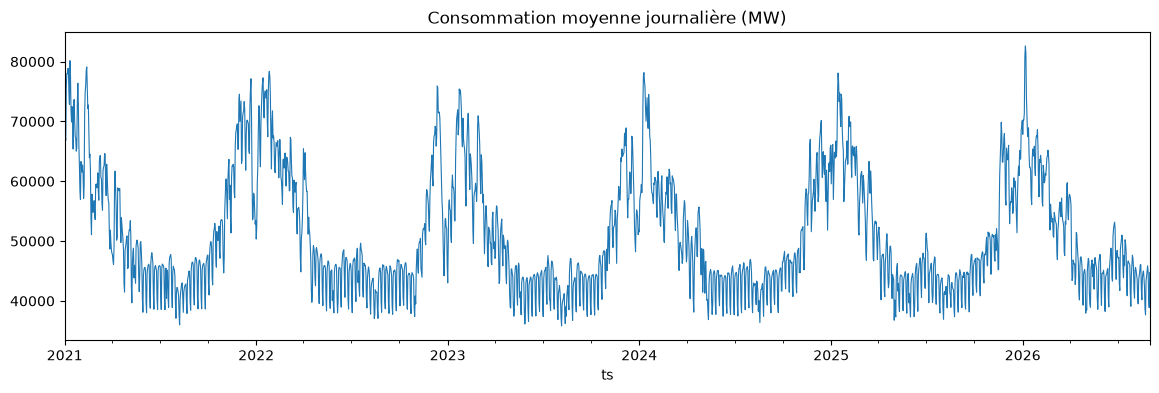

In [2]:
daily = df["consommation"].resample("D").mean()
ax = daily.plot(figsize=(14, 4), lw=0.8)
ax.set_title("Consommation moyenne journalière (MW)")
plt.show()


C:\Users\arija\AppData\Local\Temp\ipykernel_5980\18854008.py:3: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  pivot = (local.groupby([local.index.dayofweek, local.index.hour])["consommation"]


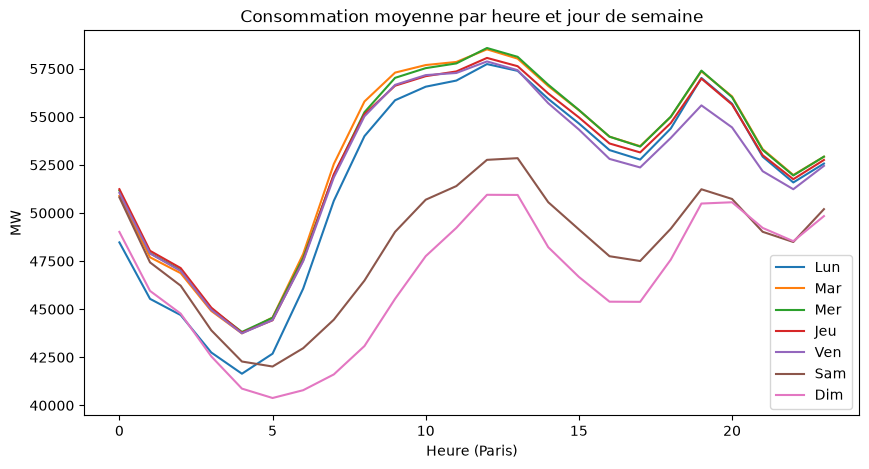

In [3]:
local = df.copy()
local.index = local.index.tz_convert("Europe/Paris")
pivot = (local.groupby([local.index.dayofweek, local.index.hour])["consommation"]
              .mean().unstack(0))
pivot.columns = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]
ax = pivot.plot(figsize=(10, 5))
ax.set_title("Consommation moyenne par heure et jour de semaine")
ax.set_xlabel("Heure (Paris)")
ax.set_ylabel("MW")
plt.show()

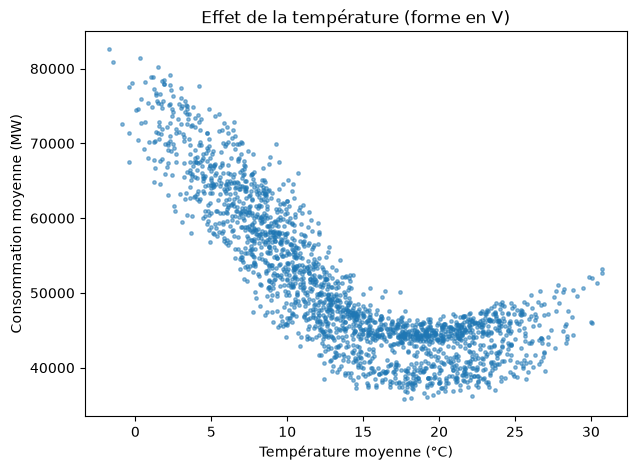

corrélation : -0.81


In [4]:
d = df[["consommation", "temp"]].resample("D").mean().dropna()
plt.figure(figsize=(7, 5))
plt.scatter(d["temp"], d["consommation"], s=6, alpha=0.5)
plt.xlabel("Température moyenne (°C)")
plt.ylabel("Consommation moyenne (MW)")
plt.title("Effet de la température (forme en V)")
plt.show()
print("corrélation :", d.corr().loc["consommation", "temp"].round(2))